In [1]:
import torch
import torch_npu
import os
import math
import fps_cpu
from typing import Optional, Union, List, Tuple

## FPS_CPU
fps_cpu串行版，通过`import fps_cpu`调用。需用下列函数封装。`%%timeit`对比单元格的运行时间。

In [2]:
def sample_farthest_points(
    points: torch.Tensor,
    lengths: Optional[torch.Tensor] = None,
    K: Union[int, List, torch.Tensor] = 50,
    random_start_point: bool = False,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Iterative farthest point sampling algorithm [1] to subsample a set of
    K points from a given pointcloud. At each iteration, a point is selected
    which has the largest nearest neighbor distance to any of the
    already selected points.

    Farthest point sampling provides more uniform coverage of the input
    point cloud compared to uniform random sampling.

    [1] Charles R. Qi et al, "PointNet++: Deep Hierarchical Feature Learning
        on Point Sets in a Metric Space", NeurIPS 2017.

    Args:
        points: (N, P, D) array containing the batch of pointclouds
        lengths: (N,) number of points in each pointcloud (to support heterogeneous
            batches of pointclouds)
        K: samples required in each sampled point cloud (this is typically << P). If
            K is an int then the same number of samples are selected for each
            pointcloud in the batch. If K is a tensor is should be length (N,)
            giving the number of samples to select for each element in the batch
        random_start_point: bool, if True, a random point is selected as the starting
            point for iterative sampling.

    Returns:
        selected_points: (N, K, D), array of selected values from points. If the input
            K is a tensor, then the shape will be (N, max(K), D), and padded with
            0.0 for batch elements where k_i < max(K).
        selected_indices: (N, K) array of selected indices. If the input
            K is a tensor, then the shape will be (N, max(K), D), and padded with
            -1 for batch elements where k_i < max(K).
    """
    N, P, D = points.shape
    device = points.device
    # import pdb; pdb.set_trace()
    # Validate inputs
    if lengths is None:
        lengths = torch.full((N,), P, dtype=torch.int64, device=device)
    else:
        if lengths.shape != (N,):
            raise ValueError("points and lengths must have same batch dimension.")
        if lengths.max() > P:
            raise ValueError("A value in lengths was too large.")

    # TODO: support providing K as a ratio of the total number of points instead of as an int
    if isinstance(K, int):
        K = torch.full((N,), K, dtype=torch.int64, device=device)
    elif isinstance(K, list):
        K = torch.tensor(K, dtype=torch.int64, device=device)

    

    if K.shape[0] != N:
        raise ValueError("K and points must have the same batch dimension")

    # Check dtypes are correct and convert if necessary
    if not (points.dtype == torch.float32):
        points = points.to(torch.float32)
    if not (lengths.dtype == torch.int64):
        lengths = lengths.to(torch.int64)
    if not (K.dtype == torch.int64):
        K = K.to(torch.int64)

    # Generate the starting indices for sampling
    start_idxs = torch.zeros_like(lengths)
    if random_start_point:
        for n in range(N):
            # pyre-fixme[6]: For 1st param expected `int` but got `Tensor`.
            start_idxs[n] = torch.randint(high=lengths[n], size=(1,)).item()

    with torch.no_grad():
        # pyre-fixme[16]: `pytorch3d_._C` has no attribute `sample_farthest_points`.
        idx = fps_cpu.farthest_point_sampling_cpu_small(points, lengths, K, start_idxs)
    # sampled_points = masked_gather(points, idx)ffff

    return idx

In [3]:
def fps_fallback(x, batch=None, ratio=0.25, random_start=True):
    """
    PyTorch fallback version of torch_cluster.fps (Furthest Point Sampling)

    Args:
        x (Tensor): (N, D) point positions
        batch (LongTensor): (N,) batch indices or None
        ratio (float): sampling ratio ∈ (0, 1]
        random_start (bool): whether to randomly initialize the first point

    Returns:
        Tensor: (M,) indices of sampled points (subset of input x)
    """
    if batch is None:
        batch = torch.zeros(x.size(0), dtype=torch.long, device=x.device)

    batch_size = batch.max().item() + 1
    output_idx = []

    for b in range(batch_size):
        mask = batch == b
        pts = x[mask]
        N = pts.size(0)
        M = max(1, math.ceil(N * ratio))  # 至少采样1个点,follow torch_cluster, 向上取整

        centroids = torch.zeros(M, dtype=torch.long, device=x.device)
        distance = torch.full((N,), 1e10, device=x.device)
        if random_start:
            farthest = torch.randint(0, N, (1,), device=x.device).item()
        else:
            farthest = 0

        for i in range(M):   
            centroids[i] = farthest
            centroid = pts[farthest].unsqueeze(0)
            dist = torch.sum((pts - centroid) ** 2, dim=1)
            mask_dist = dist < distance
            distance[mask_dist] = dist[mask_dist]
            farthest = torch.argmax(distance).item()

        batch_indices = torch.where(mask)[0][centroids]  # 恢复原始索引
        output_idx.append(batch_indices)

    return torch.cat(output_idx, dim=0)

In [4]:
n_iter = 10
n_pts = 100000
num_latent = 2048
pos = torch.rand(n_pts,3,dtype=torch.float32)
batch = torch.zeros([n_pts],dtype=torch.long)
ratio = 1.0 * num_latent / n_pts
device = torch.device('npu:0')
os.environ["OMP_NUM_THREADS"] = "16"  # 使用4个线程
torch.set_num_threads(16)  # 设置PyTorch的CPU线程数

In [5]:
%%timeit
idx_fps_fallback = fps_fallback(pos.to(device), batch=batch.to(device), ratio=ratio,random_start=False)

/var/tmp/ipykernel_1679852/1392210482.py:34: UserWarning: AutoNonVariableTypeMode is deprecated and will be removed in 1.10 release. For kernel implementations please use AutoDispatchBelowADInplaceOrView instead, If you are looking for a user facing API to enable running your inference-only workload, please use c10::InferenceMode. Using AutoDispatchBelowADInplaceOrView in user code is under risk of producing silent wrong result in some edge cases. See Note [AutoDispatchBelowAutograd] for more details. (Triggered internally at build/CMakeFiles/torch_npu.dir/compiler_depend.ts:74.)
  centroids[i] = farthest


1.59 s ± 85.2 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [6]:
%%timeit
idx2 = sample_farthest_points(pos.unsqueeze(0), lengths=torch.tensor([n_pts], dtype=torch.long), K=num_latent, random_start_point=False).squeeze().to(device)

1.8 s ± 65.7 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [7]:
idx_fps_fallback = fps_fallback(pos.to(device), batch=batch.to(device), ratio=ratio,random_start=False)
idx2 = sample_farthest_points(pos.unsqueeze(0), lengths=torch.tensor([n_pts], dtype=torch.long), K=num_latent, random_start_point=False).squeeze().to(device)
torch.allclose(idx_fps_fallback, idx2)

True

In [13]:
N = [(i+1)*10000 for i in range(10)]
time1 = [1.66,1.67,1.68,1.64,1.55,1.80,2.17,1.72,1.73,1.75]
time2 = [0.141,0.296,0.488,0.641,0.979, 1.05,1.21,1.78,2.11,2.53]

## Load Inline尝试
直接在代码块内编译。核心减少host2device的时间，先尝试numpy的效果。

In [ ]:
import numpy as np
def fps_numpy(x, batch=None, ratio=0.25, random_start=True):
    """
    NumPy implementation of Furthest Point Sampling (FPS)

    Args:
        x (np.ndarray): (N, D) point positions
        batch (np.ndarray): (N,) batch indices or None
        ratio (float): sampling ratio ∈ (0, 1]
        random_start (bool): whether to randomly initialize the first point

    Returns:
        np.ndarray: (M,) indices of sampled points (subset of input x)
    """
    if batch is None:
        batch = np.zeros(x.shape[0], dtype=np.int64)
    
    batch_size = np.max(batch) + 1
    output_idx = []

    for b in range(batch_size):
        mask = (batch == b)
        pts = x[mask]
        N = pts.shape[0]
        M = max(1, math.ceil(N * ratio))  # At least sample 1 point

        centroids = np.zeros(M, dtype=np.int64)
        distance = np.full(N, 1e10, dtype=np.float32)
        
        # Initialize first point
        farthest = np.random.randint(0, N) if random_start else 0

        for i in range(M):
            centroids[i] = farthest
            centroid = pts[farthest][np.newaxis, :]  # Shape (1, D)
            
            # Vectorized distance calculation
            dist = np.sum((pts - centroid) ** 2, axis=1)
            
            # Update minimum distance
            mask_dist = dist < distance
            distance[mask_dist] = dist[mask_dist]
            
            # Select farthest point
            farthest = np.argmax(distance)

        # Convert back to original indices
        batch_indices = np.where(mask)[0][centroids]
        output_idx.append(batch_indices)

    return np.concatenate(output_idx, axis=0)

In [9]:
%%timeit
idx3 = fps_numpy(pos.numpy(), batch=batch.numpy(), ratio=ratio, random_start=False)
idx3 = torch.from_numpy(idx3).long().to(device)

NameError: name 'fps_numpy' is not defined

In [8]:
from torch.utils.cpp_extension import  load_inline

In [17]:
fps_cpp_code = """
#include <torch/extension.h>
#include <arm_neon.h>
#include <vector>
#include <algorithm>
#include <limits>
#include <omp.h>
#include <nanoflann.hpp>

// 3D点云适配器
struct PointCloudAdapter {
    const float* data;
    size_t num_points;

    inline size_t kdtree_get_point_count() const { return num_points; }

    inline float kdtree_get_pt(const size_t idx, const size_t dim) const {
        return data[idx * 3 + dim];
    }

    template <class BBOX>
    bool kdtree_get_bbox(BBOX&) const { return false; }
};

// 针对3D点云优化的距离平方计算
inline float distance_squared_3d(const float* a, const float* b) {
    float dx = a[0] - b[0];
    float dy = a[1] - b[1];
    float dz = a[2] - b[2];
    return dx*dx + dy*dy + dz*dz;
}

void distance_squared_neon_fixed(
    const float* target,
    const float* points,  // 内存布局: [x0,y0,z0, x1,y1,z1,...]
    float* distances,
    size_t num_points)
{
    // 加载目标点坐标到向量寄存器
    float32x4_t target_x = vld1q_dup_f32(target);
    float32x4_t target_y = vld1q_dup_f32(target + 1);
    float32x4_t target_z = vld1q_dup_f32(target + 2);

    // 主循环：每次处理4个点
    for (size_t i = 0; i < num_points; i += 4) {
        // 加载4个点的坐标（需要手动收集非连续数据）
        float32x4_t x, y, z;
        for (int j = 0; j < 4 && (i + j) < num_points; ++j) {
            const float* p = points + (i + j) * 3;
            x[j] = p[0];
            y[j] = p[1];
            z[j] = p[2];
        }

        // 计算差值平方
        float32x4_t dx = vsubq_f32(x, target_x);
        float32x4_t dy = vsubq_f32(y, target_y);
        float32x4_t dz = vsubq_f32(z, target_z);
        
        float32x4_t dx2 = vmulq_f32(dx, dx);
        float32x4_t dy2 = vmulq_f32(dy, dy);
        float32x4_t dz2 = vmulq_f32(dz, dz);

        // 累加并存储结果
        float32x4_t sum = vaddq_f32(vaddq_f32(dx2, dy2), dz2);
        for (int j = 0; j < 4 && (i + j) < num_points; ++j) {
            distances[i + j] = sum[j];
        }
    }
}

void update_distances_neon(
    const float* last_point,      // [x0, y0, z0]
    const float* points,          // 连续存储的点云数据 [x1,y1,z1, x2,y2,z2,...]
    float* dists,
    const char* selected_mask,    // 选择掩码数组
    int64_t batch_length)
{
    // 加载目标点到向量寄存器
    float32x4_t target_x = vld1q_dup_f32(last_point);
    float32x4_t target_y = vld1q_dup_f32(last_point + 1);
    float32x4_t target_z = vld1q_dup_f32(last_point + 2);
    
    // 每次处理4个点（NEON寄存器容量）
    int64_t p = 0;
    for (; p + 3 < batch_length; p += 4) {
        // 加载掩码（将bool转换为float32x4_t）
        uint32x4_t mask = vld1q_u32(reinterpret_cast<const uint32_t*>(&selected_mask[p]));
        uint32x4_t zero_mask = vceqq_u32(mask, vdupq_n_u32(0)); // 0xFFFFFFFF对应未选中的点
        
        // 仅处理未选中的点（selected_mask[p] == false）
        if (vgetq_lane_u32(zero_mask, 0) || vgetq_lane_u32(zero_mask, 1) || 
            vgetq_lane_u32(zero_mask, 2) || vgetq_lane_u32(zero_mask, 3)) {
            
            // 加载4个点的坐标（手动收集非连续数据）
            float32x4_t px, py, pz;
            px = vsetq_lane_f32(points[p*3 + 0], px, 0);
            py = vsetq_lane_f32(points[p*3 + 1], py, 0);
            pz = vsetq_lane_f32(points[p*3 + 2], pz, 0);
            
            px = vsetq_lane_f32(points[(p+1)*3 + 0], px, 1);
            py = vsetq_lane_f32(points[(p+1)*3 + 1], py, 1);
            pz = vsetq_lane_f32(points[(p+1)*3 + 2], pz, 1);
            
            px = vsetq_lane_f32(points[(p+2)*3 + 0], px, 2);
            py = vsetq_lane_f32(points[(p+2)*3 + 1], py, 2);
            pz = vsetq_lane_f32(points[(p+2)*3 + 2], pz, 2);
            
            px = vsetq_lane_f32(points[(p+3)*3 + 0], px, 3);
            py = vsetq_lane_f32(points[(p+3)*3 + 1], py, 3);
            pz = vsetq_lane_f32(points[(p+3)*3 + 2], pz, 3);
            
            // 计算差值平方
            float32x4_t dx = vsubq_f32(px, target_x);
            float32x4_t dy = vsubq_f32(py, target_y);
            float32x4_t dz = vsubq_f32(pz, target_z);
            
            float32x4_t dx2 = vmulq_f32(dx, dx);
            float32x4_t dy2 = vmulq_f32(dy, dy);
            float32x4_t dz2 = vmulq_f32(dz, dz);
            
            // 计算距离平方
            float32x4_t new_dist = vaddq_f32(vaddq_f32(dx2, dy2), dz2);
            
            // 加载当前距离值
            float32x4_t current_dist = vld1q_f32(&dists[p]);
            
            // 条件更新：仅当(new_dist < current_dist)且(!selected_mask)时更新
            uint32x4_t update_mask = vandq_u32(
                vcltq_f32(new_dist, current_dist),
                zero_mask
            );
            
            // 混合新旧值
            float32x4_t updated_dist = vbslq_f32(update_mask, new_dist, current_dist);
            vst1q_f32(&dists[p], updated_dist);
        }
    }
    
    // 处理剩余不足4个的点（标量处理）
    for (; p < batch_length; ++p) {
        if (!selected_mask[p]) {
            float dx = points[p*3] - last_point[0];
            float dy = points[p*3 + 1] - last_point[1];
            float dz = points[p*3 + 2] - last_point[2];
            float new_dist = dx*dx + dy*dy + dz*dz;
            
            if (new_dist < dists[p]) {
                dists[p] = new_dist;
            }
        } else {
            dists[p] = 0.0f;
        }
    }
}


torch::Tensor farthest_point_sampling_cpu_optimized(
    const torch::Tensor& points,
    const torch::Tensor& lengths,
    const torch::Tensor& K,
    const torch::Tensor& start_idxs) {
  
    // 输入验证
    TORCH_CHECK(points.dim() == 3, "points must be 3D tensor");
    TORCH_CHECK(points.size(2) == 3, "points must have 3 dimensions (x,y,z)");
    TORCH_CHECK(lengths.dim() == 1, "lengths must be 1D tensor");
    TORCH_CHECK(K.dim() == 1, "K must be 1D tensor");
    TORCH_CHECK(start_idxs.dim() == 1, "start_idxs must be 1D tensor");
    TORCH_CHECK(points.size(0) == lengths.size(0), "batch size mismatch");
    
    const int64_t N = points.size(0);
    const int64_t P = points.size(1);
    const int64_t max_K = torch::max(K).item<int64_t>();

    // 输出张量 (N, max_K)
    auto long_opts = lengths.options();
    torch::Tensor sampled_indices = torch::full({N, max_K}, -1, long_opts);

    // 访问器
    auto points_a = points.accessor<float, 3>();
    auto lengths_a = lengths.accessor<int64_t, 1>();
    auto k_a = K.accessor<int64_t, 1>();
    auto sampled_indices_a = sampled_indices.accessor<int64_t, 2>();
    auto start_idxs_a = start_idxs.accessor<int64_t, 1>();

    // 为每个batch并行处理
    
    for (int64_t n = 0; n < N; ++n) {
        const int64_t batch_length = lengths_a[n];
        const int64_t batch_k = std::min(batch_length, k_a[n]);
        
        // 使用vector<bool>更节省空间
        std::vector<char> selected_points_mask(batch_length, 0); // 0=false, 1=true
        std::vector<float> dists(batch_length, std::numeric_limits<float>::max());

        // 初始点
        int64_t last_idx = start_idxs_a[n];
        sampled_indices_a[n][0] = last_idx;
        selected_points_mask[last_idx] = true;

        // 预加载上一个点的坐标
        const float* last_point = &points_a[n][last_idx][0];

        // 计算初始距离
        // #pragma omp simd
        // for (int64_t p = 0; p < batch_length; ++p) {
        //     dists[p] = distance_squared_3d(last_point, &points_a[n][p][0]);
        // }
        distance_squared_neon_fixed(last_point, &points_a[n][0][0], dists.data(), batch_length);

        // 迭代采样剩余点
        for (int64_t k = 1; k < batch_k; ++k) {
            // 找到最远点
            int64_t farthest_idx = std::distance(
                dists.begin(), 
                std::max_element(dists.begin(), dists.end()));
            
            sampled_indices_a[n][k] = farthest_idx;
            selected_points_mask[farthest_idx] = true;
            
            // 更新last_point
            last_point = &points_a[n][farthest_idx][0];
            
            // 更新距离
            update_distances_neon(
                last_point,                // 当前采样点坐标
                &points_a[n][0][0],        // 点云数据起始指针
                dists.data(),              // 距离数组
                selected_points_mask.data(), // 选择掩码
                batch_length               // 点数量
            );
        }
    }
    
    return sampled_indices;
}

torch::Tensor farthest_point_sampling_cpu_kdtree(
    const torch::Tensor& points,
    const torch::Tensor& lengths,
    const torch::Tensor& K,
    const torch::Tensor& start_idxs) {
  
    // 输入验证
    TORCH_CHECK(points.dim() == 3, "points must be 3D tensor");
    TORCH_CHECK(points.size(2) == 3, "points must have 3 dimensions (x,y,z)");
    TORCH_CHECK(lengths.dim() == 1, "lengths must be 1D tensor");
    TORCH_CHECK(K.dim() == 1, "K must be 1D tensor");
    TORCH_CHECK(start_idxs.dim() == 1, "start_idxs must be 1D tensor");
    TORCH_CHECK(points.size(0) == lengths.size(0), "batch size mismatch");
    
    const int64_t N = points.size(0);
    const int64_t P = points.size(1);
    const int64_t max_K = torch::max(K).item<int64_t>();

    // 输出张量 (N, max_K)
    auto long_opts = lengths.options();
    torch::Tensor sampled_indices = torch::full({N, max_K}, -1, long_opts);

    // 访问器
    auto points_a = points.accessor<float, 3>();
    auto lengths_a = lengths.accessor<int64_t, 1>();
    auto k_a = K.accessor<int64_t, 1>();
    auto sampled_indices_a = sampled_indices.accessor<int64_t, 2>();
    auto start_idxs_a = start_idxs.accessor<int64_t, 1>();

    // 为每个batch并行处理
    
    for (int64_t n = 0; n < N; ++n) {
        const int64_t batch_length = lengths_a[n];
        const int64_t batch_k = std::min(batch_length, k_a[n]);
        
        // 初始化KD-Tree
        PointCloudAdapter pc;
        pc.data = &points_a[n][0][0];
        pc.num_points = batch_length;

        using KDTree = nanoflann::KDTreeSingleIndexAdaptor<
            nanoflann::L2_Simple_Adaptor<float, PointCloudAdapter>,
            PointCloudAdapter,
            3,
            size_t>;

        KDTree kdtree(3, pc, nanoflann::KDTreeSingleIndexAdaptorParams(10));
        kdtree.buildIndex();
        
        // 使用vector<bool>更节省空间
        std::vector<bool> selected_points_mask(batch_length, false);
        std::vector<float> dists(batch_length, std::numeric_limits<float>::max());

        // 初始点
        int64_t last_idx = start_idxs_a[n];
        sampled_indices_a[n][0] = last_idx;
        selected_points_mask[last_idx] = true;

        // 预加载上一个点的坐标
        const float* last_point = &points_a[n][last_idx][0];

        // 计算初始距离
        distance_squared_neon_fixed(last_point, &points_a[n][0][0], dists.data(), batch_length);

        // 迭代采样剩余点
        for (int64_t k = 1; k < batch_k; ++k) {
            // 使用KD-Tree进行最近邻搜索优化
            std::vector<nanoflann::ResultItem<size_t, float>> ret_matches;  // 使用nanoflann的正确返回类型

            // 查找距离当前点最远的未选择点
            size_t farthest_idx = 0;
            float max_dist = 0.0f;
            
            #pragma omp simd reduction(max:max_dist)
            for (int64_t p = 0; p < batch_length; ++p) {
                if (!selected_points_mask[p] &&
                     dists[p] > max_dist) {
                    max_dist = dists[p];
                    farthest_idx = p;
                }
            }

            // 更新选择点和距离
            sampled_indices_a[n][k] = farthest_idx;
            selected_points_mask[farthest_idx] = true;
            const float* new_point = &points_a[n][farthest_idx][0];

            // 使用KD-Tree进行半径搜索优化距离更新
            const float radius = std::sqrt(max_dist);
            kdtree.radiusSearch(
                new_point, 
                radius, 
                ret_matches, 
                nanoflann::SearchParameters(0.05, false)
            );

            #pragma omp simd
            for (size_t i = 0; i < ret_matches.size(); ++i) {
                const size_t p = ret_matches[i].first;
                if (!selected_points_mask[p]) {
                    const float new_dist = ret_matches[i].second;
                    if (new_dist < dists[p]) {
                        dists[p] = new_dist;
                    }
                }
            }
            // 处理未被半径搜索覆盖的点
            #pragma omp simd
            for (int64_t p = 0; p < batch_length; ++p) {
                if (selected_points_mask[p]) {
                    dists[p] = 0.0f;
                }
            }
        }
    }
    
    return sampled_indices;
}


PYBIND11_MODULE(TORCH_EXTENSION_NAME, m) {
    m.def("fps_v", &farthest_point_sampling_cpu_optimized,
          "Optimized FPS for 3D point clouds");
}
"""

# 编译加载
fps_extension = load_inline(
    name="inline_fps",
    cpp_sources=fps_cpp_code,
    extra_cflags=["-O3","-shared","-std=c++17","-fPIC", "-fopenmp", "-I/usr/local/include/"],
    verbose=True
)

Using /root/.cache/torch_extensions/py39_cpu as PyTorch extensions root...
The input conditions for extension module inline_fps have changed. Bumping to version 5 and re-building as inline_fps_v5...
Emitting ninja build file /root/.cache/torch_extensions/py39_cpu/inline_fps/build.ninja...
Building extension module inline_fps_v5...
Allowing ninja to set a default number of workers... (overridable by setting the environment variable MAX_JOBS=N)


[1/2] c++ -MMD -MF main.o.d -DTORCH_EXTENSION_NAME=inline_fps_v5 -DTORCH_API_INCLUDE_EXTENSION_H -DPYBIND11_COMPILER_TYPE=\"_gcc\" -DPYBIND11_STDLIB=\"_libstdcpp\" -DPYBIND11_BUILD_ABI=\"_cxxabi1011\" -isystem /home/ma-user/anaconda3/envs/PyTorch-2.1.0/lib/python3.9/site-packages/torch/include -isystem /home/ma-user/anaconda3/envs/PyTorch-2.1.0/lib/python3.9/site-packages/torch/include/torch/csrc/api/include -isystem /home/ma-user/anaconda3/envs/PyTorch-2.1.0/lib/python3.9/site-packages/torch/include/TH -isystem /home/ma-user/anaconda3/envs/PyTorch-2.1.0/lib/python3.9/site-packages/torch/include/THC -isystem /home/ma-user/anaconda3/envs/PyTorch-2.1.0/include/python3.9 -D_GLIBCXX_USE_CXX11_ABI=0 -fPIC -std=c++17 -O3 -shared -std=c++17 -fPIC -fopenmp -I/usr/local/include/ -c /root/.cache/torch_extensions/py39_cpu/inline_fps/main.cpp -o main.o 
[2/2] c++ main.o -shared -L/home/ma-user/anaconda3/envs/PyTorch-2.1.0/lib/python3.9/site-packages/torch/lib -lc10 -ltorch_cpu -ltorch -ltorch_pyth

Loading extension module inline_fps_v5...


In [18]:
def sample_farthest_points_v(
    points: torch.Tensor,
    lengths: Optional[torch.Tensor] = None,
    K: Union[int, List, torch.Tensor] = 50,
    random_start_point: bool = False,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Iterative farthest point sampling algorithm [1] to subsample a set of
    K points from a given pointcloud. At each iteration, a point is selected
    which has the largest nearest neighbor distance to any of the
    already selected points.

    Farthest point sampling provides more uniform coverage of the input
    point cloud compared to uniform random sampling.

    [1] Charles R. Qi et al, "PointNet++: Deep Hierarchical Feature Learning
        on Point Sets in a Metric Space", NeurIPS 2017.

    Args:
        points: (N, P, D) array containing the batch of pointclouds
        lengths: (N,) number of points in each pointcloud (to support heterogeneous
            batches of pointclouds)
        K: samples required in each sampled point cloud (this is typically << P). If
            K is an int then the same number of samples are selected for each
            pointcloud in the batch. If K is a tensor is should be length (N,)
            giving the number of samples to select for each element in the batch
        random_start_point: bool, if True, a random point is selected as the starting
            point for iterative sampling.

    Returns:
        selected_points: (N, K, D), array of selected values from points. If the input
            K is a tensor, then the shape will be (N, max(K), D), and padded with
            0.0 for batch elements where k_i < max(K).
        selected_indices: (N, K) array of selected indices. If the input
            K is a tensor, then the shape will be (N, max(K), D), and padded with
            -1 for batch elements where k_i < max(K).
    """
    N, P, D = points.shape
    device = points.device
    # import pdb; pdb.set_trace()
    # Validate inputs
    if lengths is None:
        lengths = torch.full((N,), P, dtype=torch.int64, device=device)
    else:
        if lengths.shape != (N,):
            raise ValueError("points and lengths must have same batch dimension.")
        if lengths.max() > P:
            raise ValueError("A value in lengths was too large.")

    # TODO: support providing K as a ratio of the total number of points instead of as an int
    if isinstance(K, int):
        K = torch.full((N,), K, dtype=torch.int64, device=device)
    elif isinstance(K, list):
        K = torch.tensor(K, dtype=torch.int64, device=device)

    

    if K.shape[0] != N:
        raise ValueError("K and points must have the same batch dimension")

    # Check dtypes are correct and convert if necessary
    if not (points.dtype == torch.float32):
        points = points.to(torch.float32)
    if not (lengths.dtype == torch.int64):
        lengths = lengths.to(torch.int64)
    if not (K.dtype == torch.int64):
        K = K.to(torch.int64)

    # Generate the starting indices for sampling
    start_idxs = torch.zeros_like(lengths)
    if random_start_point:
        for n in range(N):
            # pyre-fixme[6]: For 1st param expected `int` but got `Tensor`.
            start_idxs[n] = torch.randint(high=lengths[n], size=(1,)).item()

    with torch.no_grad():
        # pyre-fixme[16]: `pytorch3d_._C` has no attribute `sample_farthest_points`.
        idx = fps_extension.fps_v(points, lengths, K, start_idxs)
    # sampled_points = masked_gather(points, idx)

    return idx

In [19]:
%%timeit
idx4 = sample_farthest_points_v(pos.unsqueeze(0), lengths=torch.tensor([n_pts], dtype=torch.long), K=num_latent, random_start_point=False).squeeze().to(device)

2.04 s ± 105 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [20]:
idx4 = sample_farthest_points_v(pos.unsqueeze(0), lengths=torch.tensor([n_pts], dtype=torch.long), K=num_latent, random_start_point=False).squeeze().to(device)
torch.allclose(idx2, idx4)

False

In [24]:
import timeit
N = [i*10000 for i in range(2,25)]
times1 = []
times2 = []
times3 = []
device = torch.device('npu:4')
def func1(pos, n_pts, num_latent):
    return fps_fallback(pos.to(device), batch=torch.zeros([n_pts],dtype=torch.long, device=device), ratio=1.0 * num_latent / n_pts,random_start=False)

def func2(pos, n_pts, num_latent):
    return sample_farthest_points(pos.unsqueeze(0), lengths=torch.tensor([n_pts], dtype=torch.long), K=num_latent, random_start_point=False).squeeze().to(device)

def func3(pos, n_pts, num_latent):
    return sample_farthest_points_v(pos.unsqueeze(0), lengths=torch.tensor([n_pts], dtype=torch.long), K=num_latent, random_start_point=False).squeeze().to(device)

for n_pts in N:
    print(f'processing {n_pts} points')
    num_latent = 2048
    pos = torch.rand(n_pts,3,dtype=torch.float32)
    time1 = timeit.timeit(lambda: func1(pos, n_pts, num_latent), number=10) / 10 # 转换为秒
    times1.append(time1)

    time2 = timeit.timeit(lambda: func2(pos, n_pts, num_latent), number=10) / 10 # 转换为秒
    times2.append(time2)

    time3 = timeit.timeit(lambda: func3(pos, n_pts, num_latent), number=10) / 10 # 转换为秒
    times3.append(time3)

    print(f'torch version {time1:.4f} s, fps_cpu_v0.1 {time2:.4f} s, fps_cpu_v0.2 {time3:.4f} s')
    

    

processing 20000 points
torch version 1.5999 s, fps_cpu_v0.1 0.2001 s, fps_cpu_v0.2 0.2601 s
processing 30000 points
torch version 1.5953 s, fps_cpu_v0.1 0.3888 s, fps_cpu_v0.2 0.4303 s
processing 40000 points
torch version 1.6249 s, fps_cpu_v0.1 0.6468 s, fps_cpu_v0.2 0.5646 s
processing 50000 points
torch version 2.0330 s, fps_cpu_v0.1 0.8651 s, fps_cpu_v0.2 0.7407 s
processing 60000 points
torch version 2.0152 s, fps_cpu_v0.1 1.1139 s, fps_cpu_v0.2 0.8929 s
processing 70000 points
torch version 2.0659 s, fps_cpu_v0.1 1.4082 s, fps_cpu_v0.2 1.0919 s
processing 80000 points
torch version 2.0073 s, fps_cpu_v0.1 1.5430 s, fps_cpu_v0.2 1.2740 s
processing 90000 points
torch version 2.0447 s, fps_cpu_v0.1 1.7207 s, fps_cpu_v0.2 1.4426 s
processing 100000 points
torch version 1.6908 s, fps_cpu_v0.1 2.0243 s, fps_cpu_v0.2 1.5548 s
processing 110000 points
torch version 2.0472 s, fps_cpu_v0.1 2.1470 s, fps_cpu_v0.2 1.7818 s
processing 120000 points
torch version 2.1191 s, fps_cpu_v0.1 2.2377

In [25]:
import numpy as np
data = {
    'N': N,
    'time_torch': times1,
    'time_cpu_1': times2,
    'time_cpu_2': times3,
}
np.savez('time_res_3.npz', **data)

In [26]:
import numpy as np
data = np.load('time_res_3.npz').items()
res = {}
for k,v in data:
    res[k] = v

In [23]:
res

{'N': array([ 10000,  15000,  20000,  25000,  30000,  35000,  40000,  45000,
         50000,  55000,  60000,  65000,  70000,  75000,  80000,  85000,
         90000,  95000, 100000, 105000, 110000, 115000, 120000]),
 'time_torch': array([1.62355558, 1.63773199, 1.6695089 , 2.04498739, 1.95692406,
        1.98679811, 1.95425082, 2.02198343, 1.6980162 , 1.95594885,
        2.0507764 , 2.12149625, 2.11785413, 2.06412517, 2.07204246,
        2.16004007, 2.00292527, 2.02506018, 1.71081163, 2.07660559,
        2.0106228 , 2.00749694, 2.31642508]),
 'time_cpu_1': array([0.14054438, 0.21811309, 0.30949229, 0.38680086, 0.51940689,
        0.59983303, 0.78568308, 0.97398082, 1.00235093, 1.09683787,
        1.29760513, 1.39894186, 1.4902392 , 1.66298886, 1.78104594,
        1.85296887, 2.0567709 , 2.18373876, 2.25102976, 2.42655886,
        2.62839276, 2.72047411, 2.83980059]),
 'time_cpu_2': array([0.14172871, 0.20067895, 0.26170891, 0.33183204, 0.41363209,
        0.49656645, 0.59803945, 0.65791

In [24]:
import pandas as pd

df = pd.DataFrame(res)
df

,N,time_torch,time_cpu_1,time_cpu_2
0,10000,1.623556,0.140544,0.141729
1,15000,1.637732,0.218113,0.200679
2,20000,1.669509,0.309492,0.261709
3,25000,2.044987,0.386801,0.331832
4,30000,1.956924,0.519407,0.413632
5,35000,1.986798,0.599833,0.496566
6,40000,1.954251,0.785683,0.598039
7,45000,2.021983,0.973981,0.657914
8,50000,1.698016,1.002351,0.747864
9,55000,1.955949,1.096838,0.806153


<Axes: xlabel='N', ylabel='time(s)'>

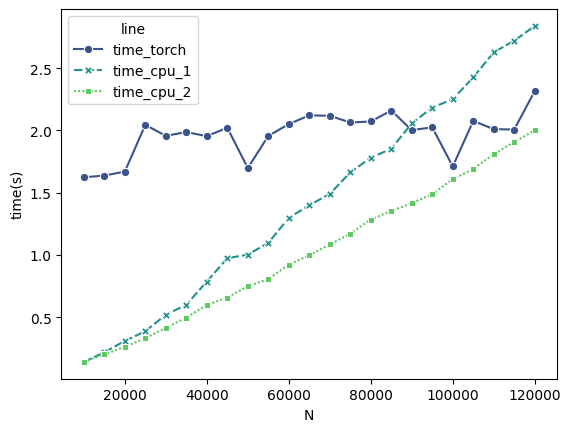

In [25]:
import seaborn as sns
df_melted = df.melt(id_vars='N', var_name='line', value_name='time(s)')
sns.lineplot(data=df_melted, x='N', y='time(s)', hue='line', style='line', markers=True, palette='viridis')

## 多线程尝试

In [ ]:
import torch
import torch_npu

from timeit import timeit
import matplotlib.pyplot as plt

# 生成测试数据
n_pts = 50000
points = torch.randn(n_pts, 3).npu() if torch.npu.is_available() else torch.randn(50000, 3)
lengths = torch.tensor([n_pts])
K = torch.tensor([2048])
start_idxs = torch.tensor([0])

# 测试函数
def run_fps():
    return sample_farthest_points_v(points.unsqueeze(0), lengths=torch.tensor([n_pts], dtype=torch.long), K=K, random_start_point=False).squeeze().to(device)

# 多线程测试
thread_counts = [1, 2, 4, 8]
timings = []

for threads in thread_counts:
    # 设置线程数（必须在每个测试前设置）
    import os
    os.environ['OMP_NUM_THREADS'] = str(threads)
    
    # 预热（避免首次运行开销）
    _ = run_fps()
    
    # 正式计时（重复5次取平均）
    t = timeit(
        'run_fps()', 
        setup='from __main__ import run_fps', 
        number=5
    ) / 5
    
    timings.append(t)
    print(f"Threads={threads}, Time={t:.3f}s")

# 绘制结果
plt.plot(thread_counts, timings, 'o-')
plt.xlabel('Number of Threads')
plt.ylabel('Time (s)')
plt.title('FPS Scaling with Threads')
plt.show()